# ERA5-pretrained stages vs. global conventional obs

Compares forecast error against the same conventional-obs verification for the five
ERA5-pretrained stages, all under

`/pscratch/sd/b/bhuang95/nested-eagle/0.25deg-06km/production/era5-gfs-hrrr/stage2c/diagnostics/`

| experiment | model | obs-metrics file tag |
|---|---|---|
| `inference-era5-gfs-hrrr-stage1a` | global, 1.00° grid | `convobs.global` |
| `inference-era5-gfs-hrrr-stage1b` | global, 0.25° grid | `convobs.global` |
| `inference-era5-gfs-hrrr-stage2a` | nested cutout (GFS + HRRR) | `convobs.nested-global` |
| `inference-era5-gfs-hrrr-stage2b` | nested cutout (GFS + HRRR) | `convobs.nested-global` |
| `inference-era5-gfs-hrrr-stage2c` | nested cutout (GFS + HRRR) | `convobs.nested-global` |

**Two things to know before reading the plots.**

1. **The file tag differs by stage.** stage1a/1b write `*.convobs.global*.nc`; stage2a/2b/2c
   write `*.convobs.nested-global*.nc`. The loader below picks the right tag per experiment,
   which is why a single f-string (as in the older version of this notebook) will not work.
2. **The variable sets differ.** stage1a/1b omit `geopotential_height` and
   `2m_specific_humidity` — the ERA5 checkpoints carry `geopotential` (m²/s²) with no
   conversion in the obs registry, and have no 2 m humidity variable. The main figures
   therefore plot only variables **common to all five**; the two stage2-only variables get
   their own section at the end.

All five share the same verification period (113 inits, 2017-02-01T06 → 2018-01-31T06,
78 h apart), the same 61 lead times out to 360 h, and the same 4 pressure levels, so the
curves are directly comparable.

In [1]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xarray as xr

# niceplots.py lives in the shared baselines directory, not next to this notebook
NICEPLOTS_DIR = os.path.abspath("../../../../../baselines")
if NICEPLOTS_DIR not in sys.path:
    sys.path.insert(0, NICEPLOTS_DIR)

import niceplots
from niceplots import plot_surface_vars, plot_level_vars, nice_names, get_units

# ~/nice.mplstyle is not present on Perlmutter; fall back rather than raising
try:
    plt.style.use("~/nice.mplstyle")
except OSError:
    plt.rcParams.update({
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.grid": True,
        "grid.color": "#e6e5e1",   # recessive grid
        "grid.linewidth": 0.8,
        "axes.edgecolor": "#c3c2b7",
        "axes.linewidth": 0.8,
        "lines.linewidth": 2.0,
        "font.size": 12,
    })

In [2]:
DIAGDIR = "/pscratch/sd/b/bhuang95/nested-eagle/0.25deg-06km/production/era5-gfs-hrrr/stage2c/diagnostics"
FIGDIR = "figures"
os.makedirs(FIGDIR, exist_ok=True)

# label -> (experiment directory, obs-metrics file tag)
# The tag is NOT the same for every stage: stage1a/1b are plain global grids,
# stage2a/b/c are nested cutout grids.
EXPERIMENTS = {
    "Stage 1a": ("inference-era5-gfs-hrrr-stage1a", "global"),
    "Stage 1b": ("inference-era5-gfs-hrrr-stage1b", "global"),
    "Stage 2a": ("inference-era5-gfs-hrrr-stage2a", "nested-global"),
    "Stage 2b": ("inference-era5-gfs-hrrr-stage2b", "nested-global"),
    "Stage 2c": ("inference-era5-gfs-hrrr-stage2c", "nested-global"),
}

# "" is the global evaluation; the others are the subregions obs-metrics wrote
#SUBREGIONS = ["", ".northern_hemisphere", ".southern_hemisphere", ".tropics", ".conus"]
SUBREGIONS = [".europe"]
SUBREGION = ".europe"   # the one the interactive figures below use

In [3]:
# Stage colors, as specified: orange / red / light green / blue / black, all solid lines.
# Keep in sync with plot_metrics_vs_lam_obs_06km.ipynb — a stage must be the same series in both notebooks.
#
# Every pair separates well, in normal vision (worst OKLab dE 21.0, floor 15) and under
# simulated CVD (worst dE 10.5, target 8) — orange vs red is clear at dE 26.3 protan. The
# one caveat is weight, not hue: light green sits at 1.42:1 contrast against white and
# orange at 1.97:1, so those two lines read faint where curves overlap. The table view at
# the end gives the numbers when the curves are too close to separate by eye.
STYLE = {
    "Stage 1a": ("orange", "-"),
    "Stage 1b": ("red", "-"),
    "Stage 2a": ("lightgreen", "-"),
    "Stage 2b": ("blue", "-"),
    "Stage 2c": ("black", "-"),
}

In [4]:
def single_plot(ax, dsdict, metric_name, varname, sel=None, **kwargs):
    """Same as niceplots.single_plot, plus a per-series linestyle.

    niceplots.single_plot colors by substring match in get_color(), which returns one
    color for every label here ("NE-era5..." style names), and it has no second visual
    channel. Patching it in is cleaner than forking the whole module: plot_surface_vars
    and plot_level_vars look this name up in the niceplots namespace at call time, so
    they pick up this version and keep their own layout and legend handling.
    """
    estimator = kwargs.pop("estimator", "median")
    for label, xds in dsdict.items():
        plotme = xds[varname] if sel is None else xds[varname].sel(**sel)
        df = plotme.to_dataframe().reset_index()
        color, linestyle = STYLE.get(label, (None, "-"))
        sns.lineplot(
            data=df,
            x="fhr",
            y=varname,
            ax=ax,
            label=label,
            color=color,
            linestyle=linestyle,
            estimator=estimator,
            **kwargs,
        )
    xticks = plotme.fhr.values
    xticklabels = [str(xx) for xx in xticks]
    xlabel = "Lead Time (hours)"
    if len(xticks) > 10:
        xticks = np.concatenate([[xticks[0]], xticks[4::4]])
        xticklabels = [str(int(xx / 24)) for xx in xticks]
        xlabel = "Lead Time (days)"

    ax.set(
        ylabel=metric_name if ax.get_subplotspec().is_first_col() else "",
        xlabel=xlabel if ax.get_subplotspec().is_last_row() else "",
        title=f"{nice_names(varname)}  ({get_units(varname)})" if ax.get_subplotspec().is_first_row() else "",
        xticks=xticks,
        xticklabels=xticklabels,
    )
    ax.legend(frameon=False)


niceplots.single_plot = single_plot

In [5]:
def load(metric, subregion=SUBREGION, experiments=EXPERIMENTS):
    """Load one metric for every experiment, handling the per-stage file tag."""
    out = {}
    for label, (subdir, tag) in experiments.items():
        path = f"{DIAGDIR}/{subdir}/obs-metrics/{metric}.convobs.{tag}{subregion}.nc"
        out[label] = xr.load_dataset(path, decode_timedelta=True)
    return out


def common_vars(dsdict, candidates):
    """Keep only the candidate variables present in *every* dataset, in order."""
    shared = set.intersection(*(set(ds.data_vars) for ds in dsdict.values()))
    return tuple(v for v in candidates if v in shared)


SURFACE_CANDIDATES = ("surface_pressure", "10m_wind_speed", "2m_temperature", "2m_specific_humidity")
LEVEL_CANDIDATES = ("geopotential_height", "wind_speed", "temperature", "specific_humidity")

In [6]:
rmse = load("rmse")
mae = load("mae")

SURFACE_VARS = common_vars(rmse, SURFACE_CANDIDATES)
LEVEL_VARS = common_vars(rmse, LEVEL_CANDIDATES)

for label, ds in rmse.items():
    missing = sorted(set(SURFACE_CANDIDATES + LEVEL_CANDIDATES) - set(ds.data_vars))
    print(f"{label}: {ds.sizes['t0']} inits, fhr {ds.fhr.values[0]}-{ds.fhr.values[-1]}h, "
          f"levels {list(ds.level.values)}" + (f", missing {missing}" if missing else ""))

print(f"\nplotting surface vars: {SURFACE_VARS}")
print(f"plotting level vars:   {LEVEL_VARS}")

Stage 1a: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)], missing ['2m_specific_humidity', 'geopotential_height']
Stage 1b: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)], missing ['2m_specific_humidity', 'geopotential_height']
Stage 2a: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)]
Stage 2b: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)]
Stage 2c: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)]

plotting surface vars: ('surface_pressure', '10m_wind_speed', '2m_temperature')
plotting level vars:   ('wind_speed', 'temperature', 'specific_humidity')


## Surface variables

/global/u1/b/bhuang95/sorc/fromTim/era5-pretraining/nested-eagle-TimRepo/0.25deg-06km/baselines/niceplots.py:53: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=0, rect=[0, 0.1, 1, 1])


Text(0.5, 1.06, 'RMSE vs conventional obs — mean over inits (europe)')

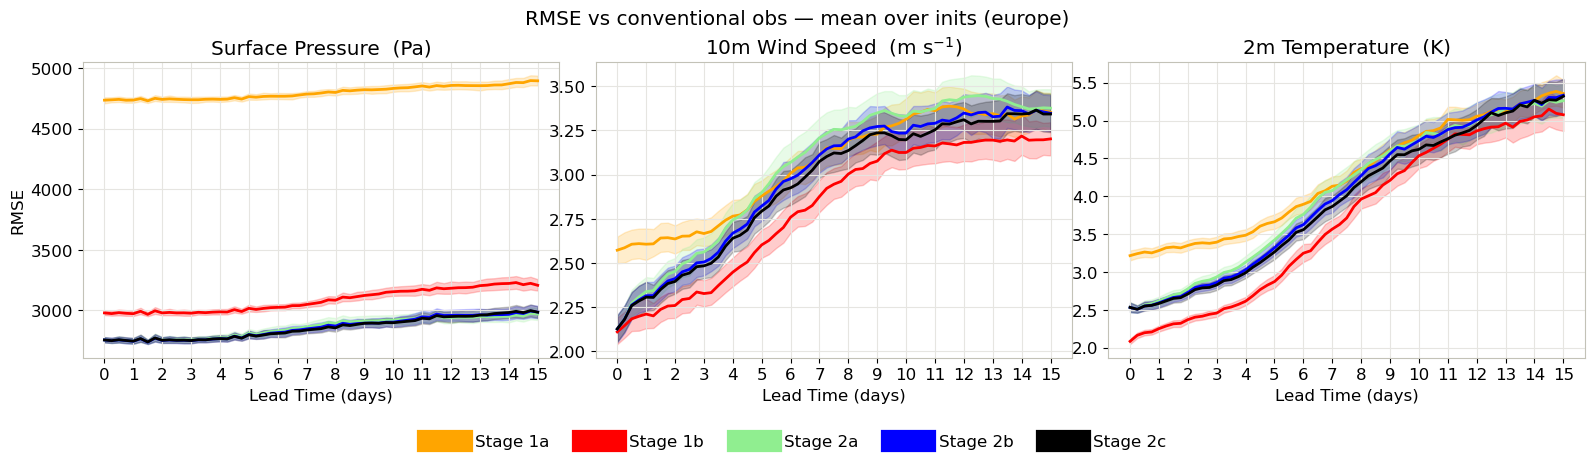

In [7]:
fig, axs = plot_surface_vars(rmse, metric_name="RMSE", surface_vars=SURFACE_VARS, estimator="mean")
fig.suptitle(f"RMSE vs conventional obs — mean over inits ({SUBREGION.lstrip('.') or 'global'})", y=1.06)

/global/u1/b/bhuang95/sorc/fromTim/era5-pretraining/nested-eagle-TimRepo/0.25deg-06km/baselines/niceplots.py:53: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=0, rect=[0, 0.1, 1, 1])


Text(0.5, 1.06, 'RMSE vs conventional obs — median over inits (europe)')

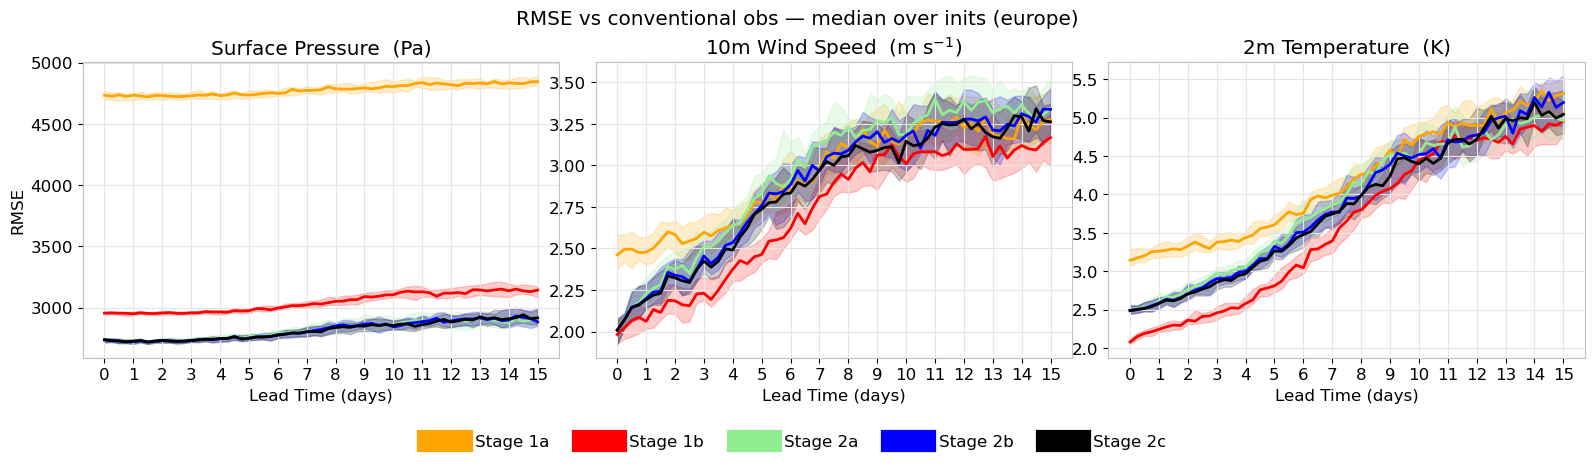

In [8]:
fig, axs = plot_surface_vars(rmse, metric_name="RMSE", surface_vars=SURFACE_VARS)
fig.suptitle(f"RMSE vs conventional obs — median over inits ({SUBREGION.lstrip('.') or 'global'})", y=1.06)

/global/u1/b/bhuang95/sorc/fromTim/era5-pretraining/nested-eagle-TimRepo/0.25deg-06km/baselines/niceplots.py:53: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=0, rect=[0, 0.1, 1, 1])


Text(0.5, 1.06, 'MAE vs conventional obs — median over inits (europe)')

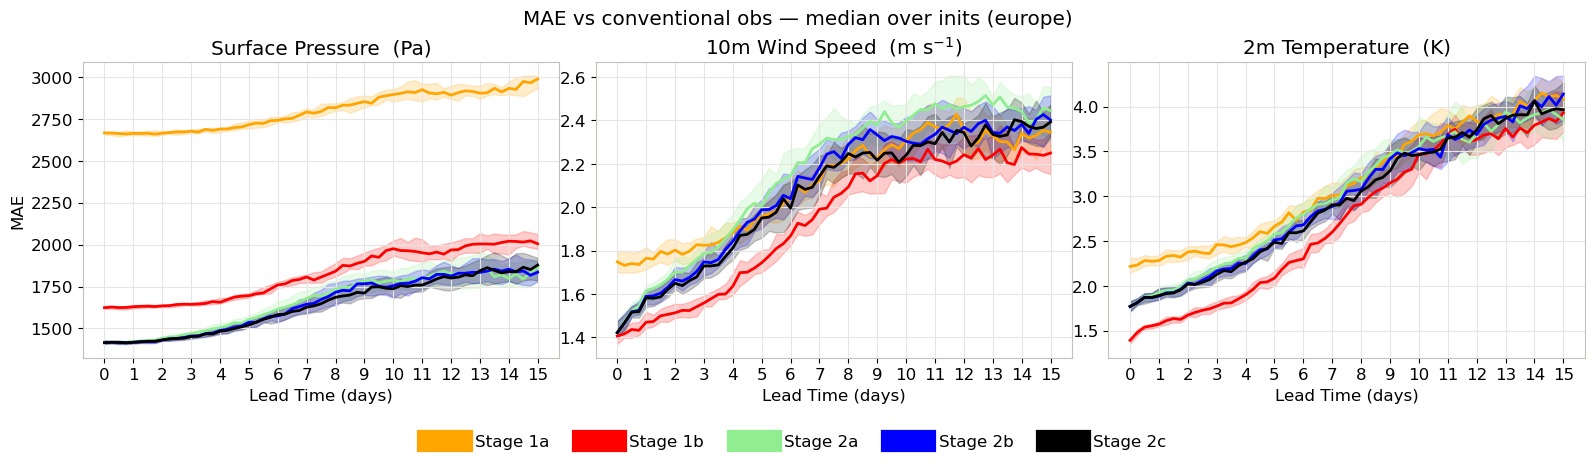

In [9]:
fig, axs = plot_surface_vars(mae, metric_name="MAE", surface_vars=SURFACE_VARS)
fig.suptitle(f"MAE vs conventional obs — median over inits ({SUBREGION.lstrip('.') or 'global'})", y=1.06)

## Pressure-level variables

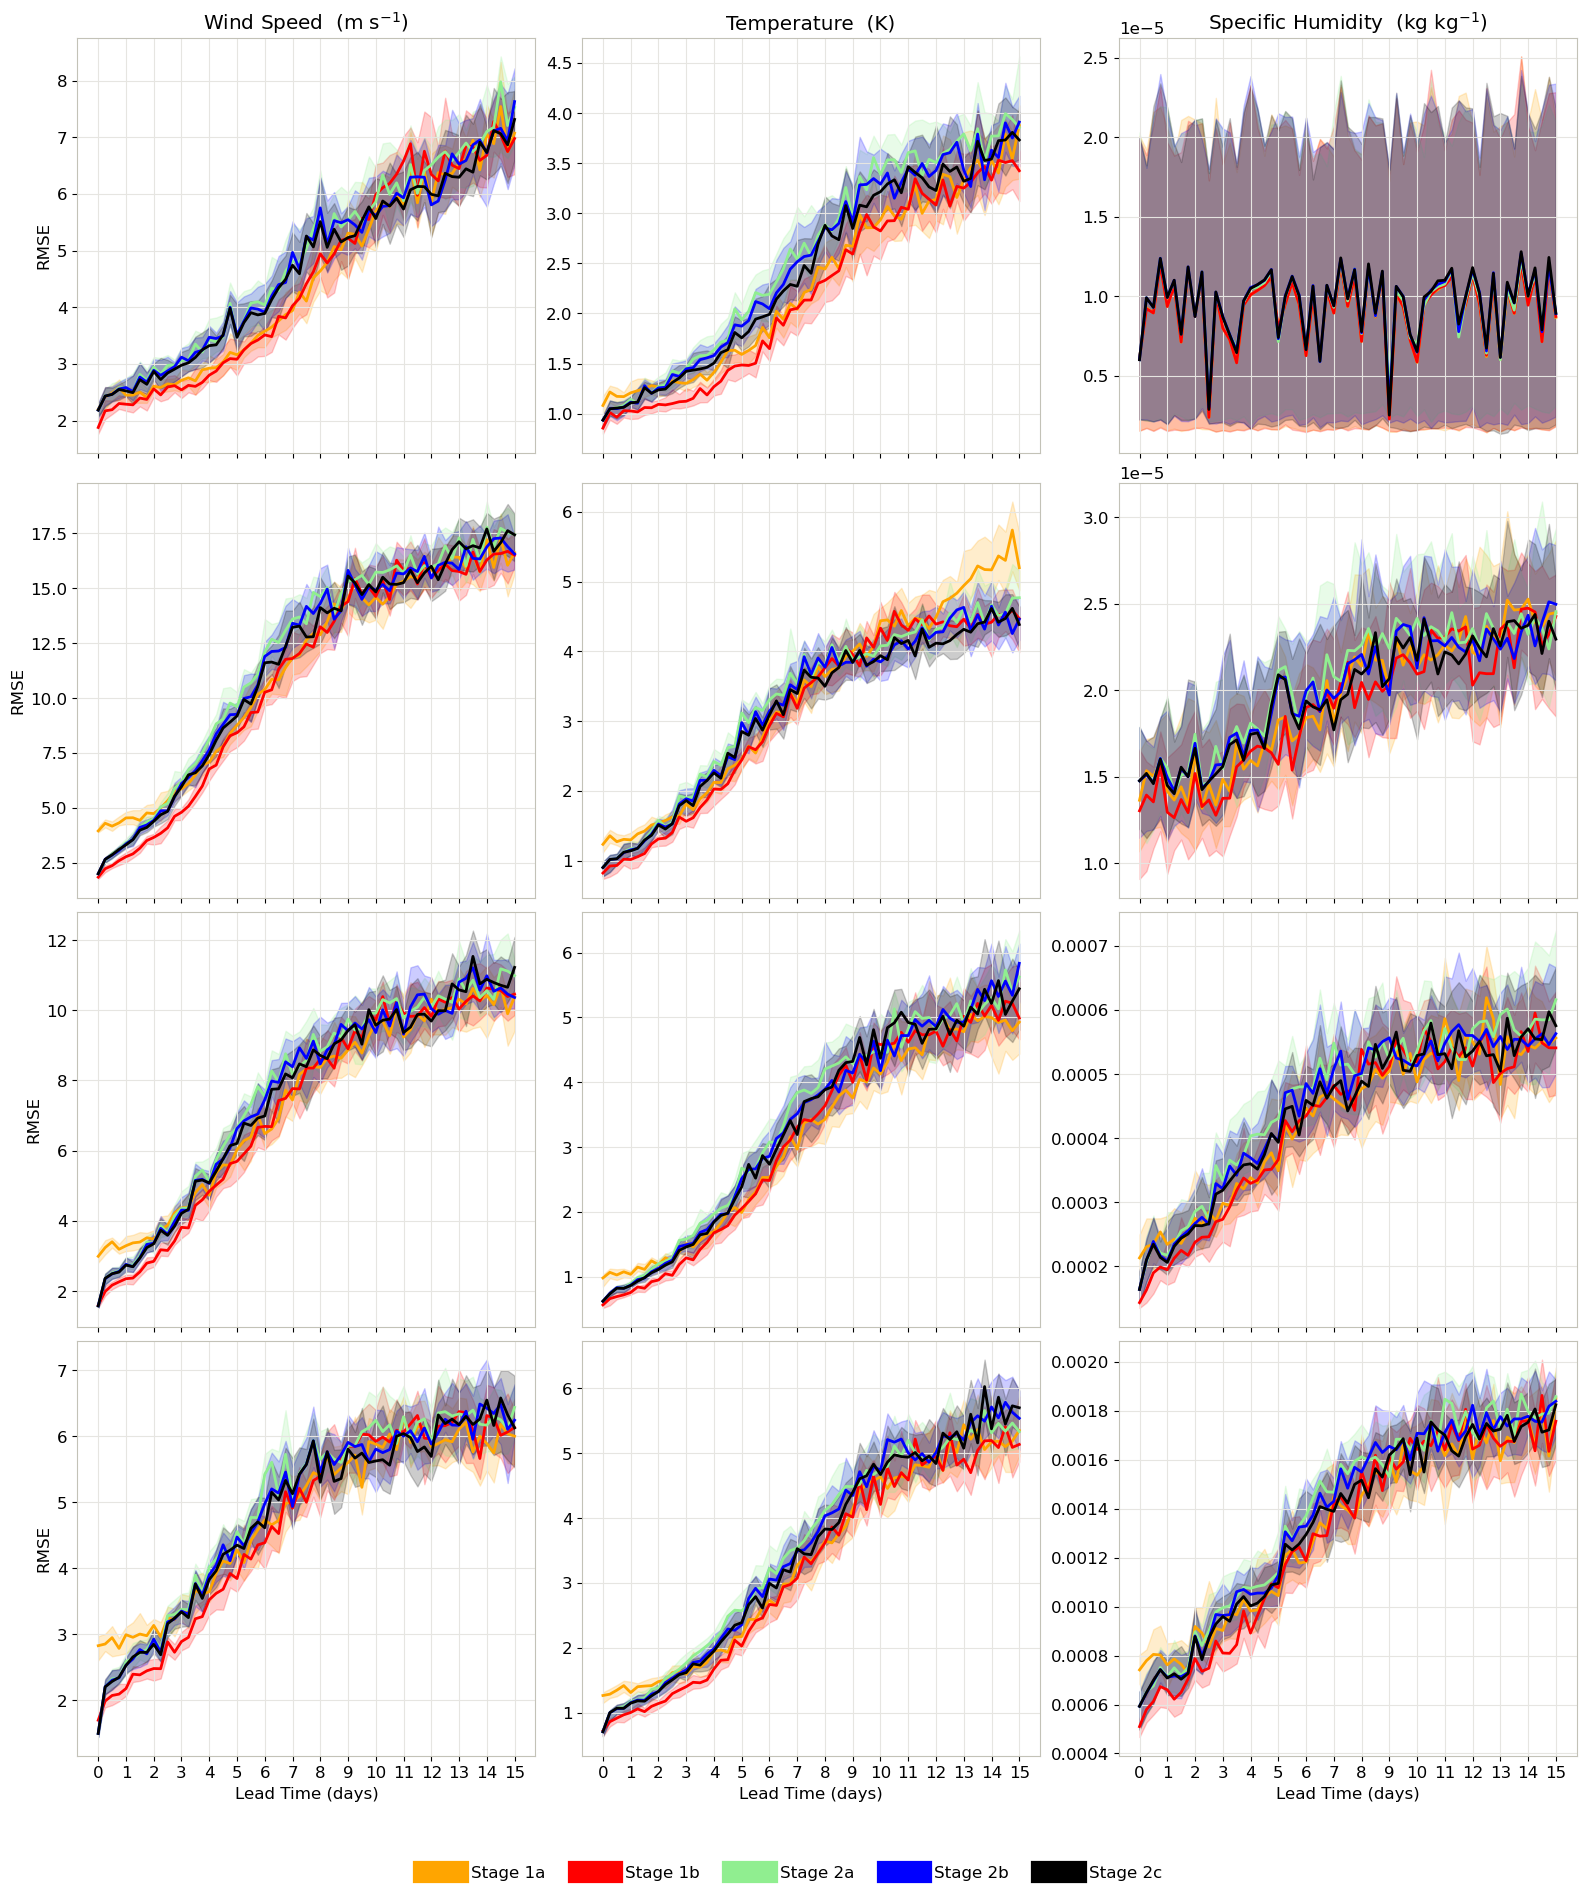

In [10]:
fig, axs = plot_level_vars(rmse, metric_name="RMSE", level_vars=LEVEL_VARS)

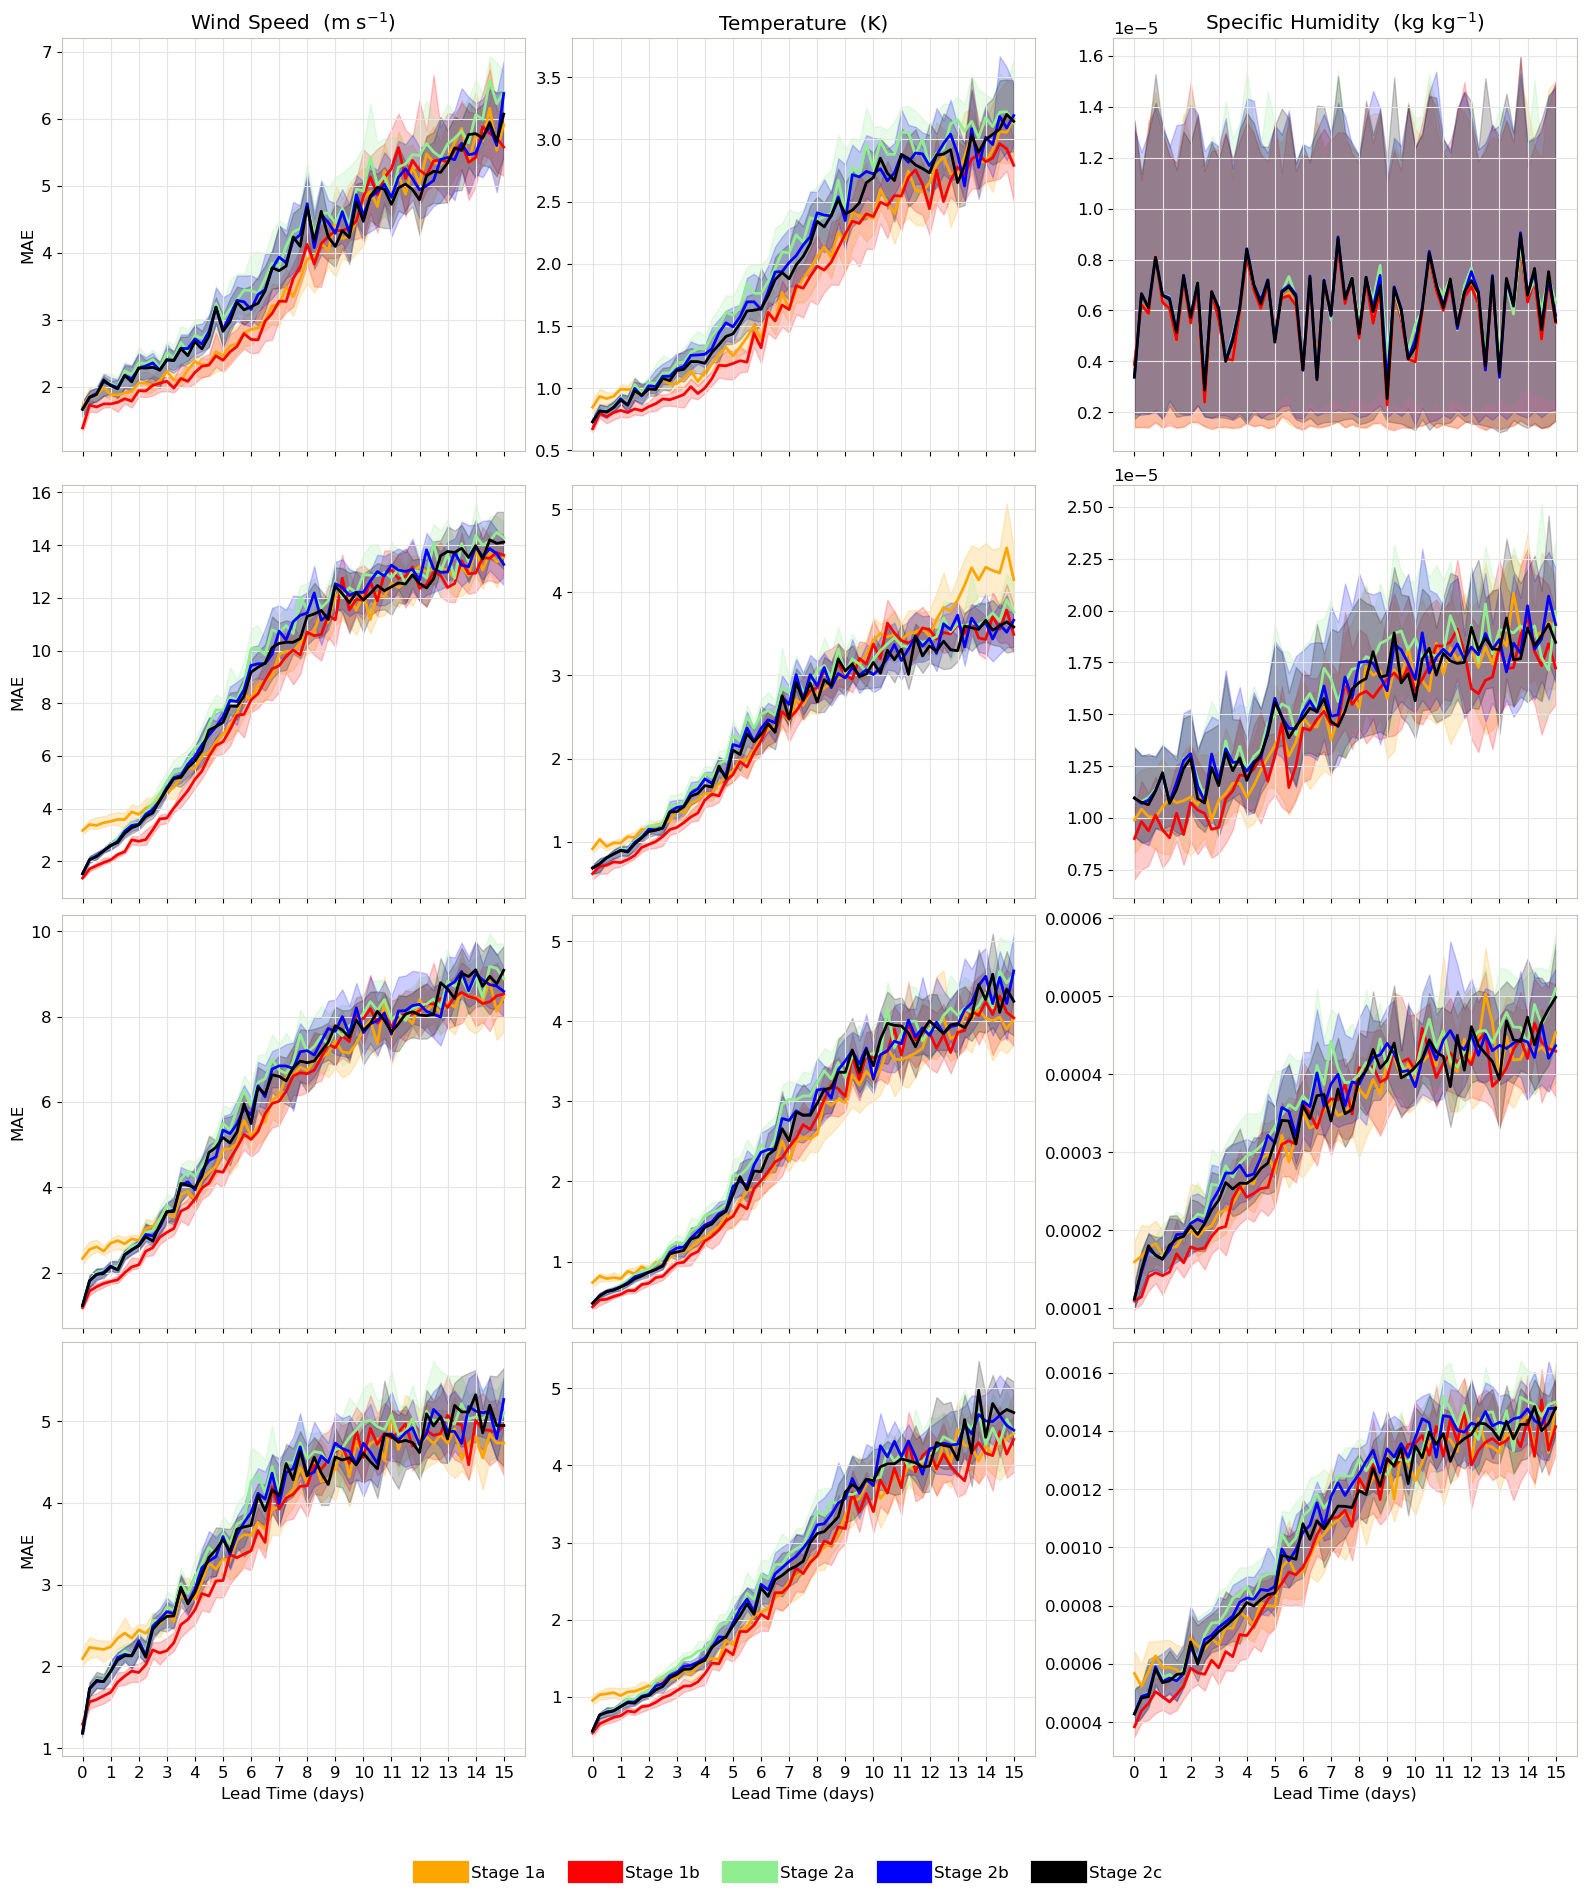

In [11]:
fig, axs = plot_level_vars(mae, metric_name="MAE", level_vars=LEVEL_VARS)

## Variables only the stage2 runs carry

`geopotential_height` and `2m_specific_humidity` exist only in stage2a/2b/2c. Each is
paired with a variable all five stages have, so the panel geometry stays valid and the
stage1 curves stay visible for context in the shared panel.

/global/u1/b/bhuang95/sorc/fromTim/era5-pretraining/nested-eagle-TimRepo/0.25deg-06km/baselines/niceplots.py:53: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=0, rect=[0, 0.1, 1, 1])


Text(0.5, 1.005, 'Stage 2 only — RMSE, pressure levels')

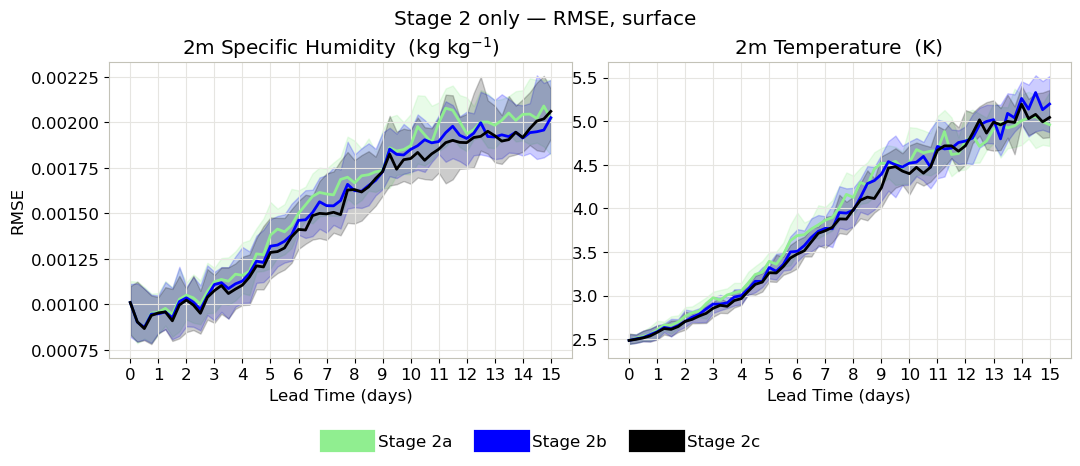

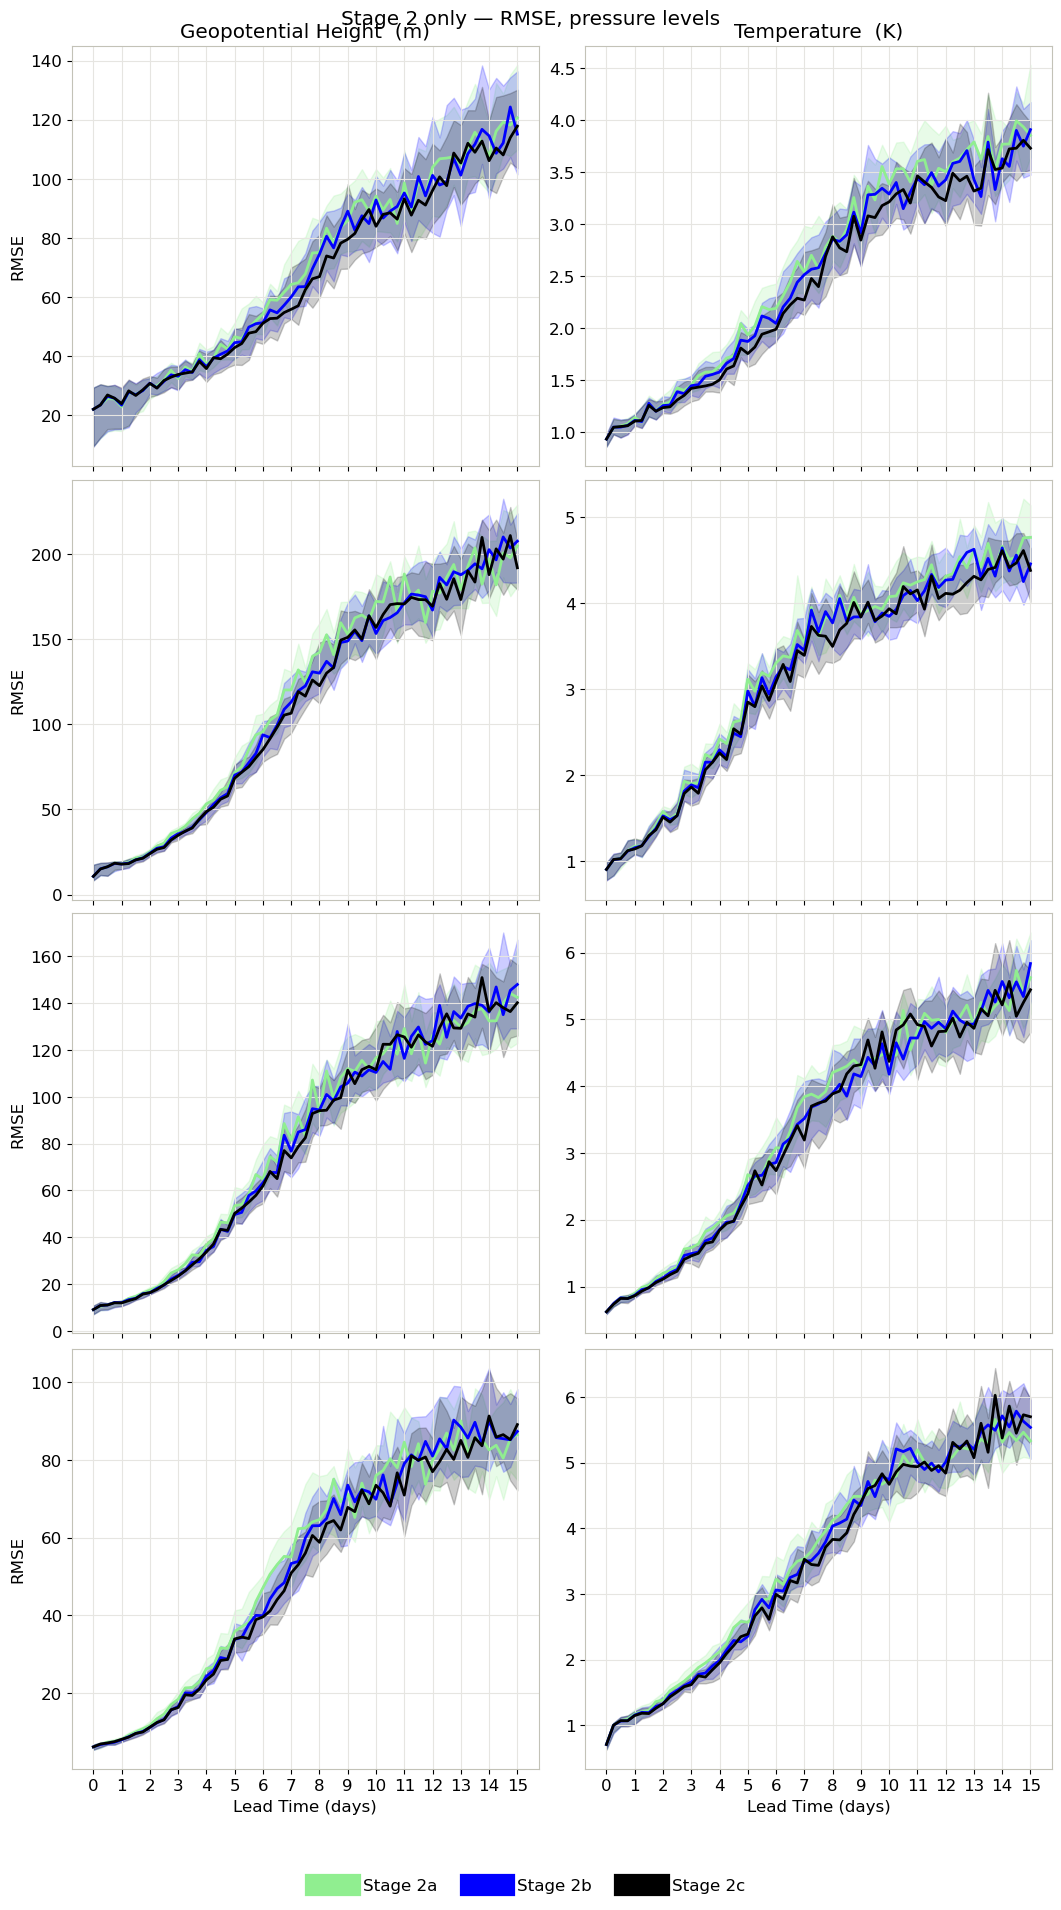

In [12]:
STAGE2 = {k: v for k, v in EXPERIMENTS.items() if k.startswith("Stage 2")}

rmse2 = load("rmse", experiments=STAGE2)

fig, axs = plot_surface_vars(
    rmse2, metric_name="RMSE", surface_vars=("2m_specific_humidity", "2m_temperature")
)
fig.suptitle("Stage 2 only — RMSE, surface", y=1.06)

fig, axs = plot_level_vars(
    rmse2, metric_name="RMSE", level_vars=("geopotential_height", "temperature")
)
fig.suptitle("Stage 2 only — RMSE, pressure levels", y=1.005)

## Table view

The numbers behind the curves at a few lead times — this is also what makes the three
lower-contrast series readable without relying on color.

In [13]:
import pandas as pd

def summary_table(dsdict, varname, fhrs=(0, 24, 72, 120, 240, 360), level=None, stat="median"):
    rows = {}
    for label, ds in dsdict.items():
        if varname not in ds.data_vars:
            continue
        da = ds[varname]
        if level is not None:
            da = da.sel(level=level)
        reduced = da.median("t0") if stat == "median" else da.mean("t0")
        rows[label] = reduced.sel(fhr=list(fhrs)).to_series()
    df = pd.DataFrame(rows)
    df.index.name = "fhr"
    return df

print("RMSE 2m_temperature (K), median over inits")
display(summary_table(rmse, "2m_temperature").round(3))

print("\nRMSE temperature @ 500 hPa (K), median over inits")
display(summary_table(rmse, "temperature", level=500).round(3))

RMSE 2m_temperature (K), median over inits


,Stage 1a,Stage 1b,Stage 2a,Stage 2b,Stage 2c
fhr,,,,,
0,3.140,2.077,2.486,2.486,2.486
24,3.260,2.242,2.608,2.585,2.578
72,3.377,2.456,2.976,2.903,2.855
120,3.603,2.809,3.393,3.322,3.262
240,4.757,4.446,4.527,4.520,4.398
360,5.315,4.954,4.960,5.197,5.043



RMSE temperature @ 500 hPa (K), median over inits


,Stage 1a,Stage 1b,Stage 2a,Stage 2b,Stage 2c
fhr,,,,,
0,0.981,0.565,0.623,0.623,0.623
24,1.038,0.757,0.896,0.871,0.863
72,1.512,1.291,1.581,1.494,1.459
120,1.991,2.051,2.675,2.513,2.386
240,4.128,4.582,4.477,4.179,4.370
360,4.928,4.991,5.624,5.835,5.442


## Save every figure, for all subregions

Writes to `figures/` next to this notebook. Same figures as above, one set per subregion.

In [14]:
def save_all(subregions=SUBREGIONS, metrics=("rmse", "mae"), figdir=FIGDIR):
    for subregion in subregions:
        data = {m: load(m, subregion=subregion) for m in metrics}
        svars = common_vars(data[metrics[0]], SURFACE_CANDIDATES)
        lvars = common_vars(data[metrics[0]], LEVEL_CANDIDATES)
        tag = f"global{subregion}"

        for metric in metrics:
            name = metric.upper()

            if metric == "rmse":
                fig, _ = plot_surface_vars(data[metric], metric_name=name,
                                           surface_vars=svars, estimator="mean")
                fig.savefig(f"{figdir}/{tag}_surface_{metric}_mean.jpeg", dpi=300, bbox_inches="tight")
                plt.close(fig)

            fig, _ = plot_surface_vars(data[metric], metric_name=name, surface_vars=svars)
            fig.savefig(f"{figdir}/{tag}_surface_{metric}.jpeg", dpi=300, bbox_inches="tight")
            plt.close(fig)

            fig, _ = plot_level_vars(data[metric], metric_name=name, level_vars=lvars)
            fig.savefig(f"{figdir}/{tag}_plevel_{metric}.jpeg", dpi=300, bbox_inches="tight")
            plt.close(fig)

        for dsdict in data.values():
            for ds in dsdict.values():
                ds.close()
        print(f"wrote {tag}")


save_all()

/global/u1/b/bhuang95/sorc/fromTim/era5-pretraining/nested-eagle-TimRepo/0.25deg-06km/baselines/niceplots.py:53: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=0, rect=[0, 0.1, 1, 1])


/global/u1/b/bhuang95/sorc/fromTim/era5-pretraining/nested-eagle-TimRepo/0.25deg-06km/baselines/niceplots.py:53: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=0, rect=[0, 0.1, 1, 1])


/global/u1/b/bhuang95/sorc/fromTim/era5-pretraining/nested-eagle-TimRepo/0.25deg-06km/baselines/niceplots.py:53: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=0, rect=[0, 0.1, 1, 1])


wrote global.europe
